# Tune and Ensemble a Classifier: Pima Diabetes
**Name:** Akshat Shah  
**Date:** October 1, 2026

**Objective:** Evaluate a baseline Decision Tree with five-fold cross-validation, tune it using **GridSearchCV AND RandomizedSearchCV**, train a Random Forest ensemble, and compare all four results on the same held-out test set.

In [ ]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
    GridSearchCV, RandomizedSearchCV, ParameterGrid)
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

SEED = 42
OUTPUT_DIR = Path("outputs")
CHART_DIR = OUTPUT_DIR / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", lambda x: f"{x:.6f}")
plt.rcParams.update({"figure.dpi":110, "axes.spines.top":False, "axes.spines.right":False})
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | sklearn {sklearn.__version__}")

def save_chart(name):
    plt.tight_layout()
    plt.savefig(CHART_DIR/name, dpi=150, bbox_inches="tight")
    plt.show()

Python 3.12.14 | pandas 2.2.3 | sklearn 1.8.0


## 1. Load and inspect the dataset

In [ ]:
candidates = [Path("data/diabetes.csv"), Path("diabetes.csv"), Path("/content/diabetes.csv")]
if Path("/kaggle/input").exists():
    candidates += sorted(Path("/kaggle/input").rglob("diabetes.csv"))
data_path = next((p for p in candidates if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError("Upload or attach the supplied diabetes.csv; see the submission guide.")
raw = pd.read_csv(data_path)
print("Loaded:", data_path, "| Shape:", raw.shape)
input_hash = hashlib.sha256(data_path.read_bytes()).hexdigest()
print("SHA256:", input_hash)
feature_names = ["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin","BMI","DiabetesPedigreeFunction","Age"]
assert set(raw.columns)==set(feature_names+["Outcome"])
assert raw["Outcome"].notna().all() and set(raw["Outcome"].unique())=={0,1}
display(raw.head())
display(raw.isna().sum().rename("Initial missing count").to_frame())
duplicates_removed = int(raw.duplicated().sum())
df = raw.drop_duplicates().copy()
print("Exact duplicate rows removed:", duplicates_removed)
display(df.describe())
display(df["Outcome"].value_counts().sort_index().rename("Class count").to_frame())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.600000,0.627000,50,1
1,1,85,66,29,0,26.600000,0.351000,31,0
2,8,183,64,0,0,23.300000,0.672000,32,1
3,1,89,66,23,94,28.100000,0.167000,21,0
4,0,137,40,35,168,43.100000,2.288000,33,1


,Initial missing count
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


,Class count
Outcome,
0,500
1,268


Loaded: data/diabetes.csv | Shape: (768, 9)
SHA256: b78029447fae2743b3218bb2b76ef0d04afe8d7e55ce2faf4d1ec82d8f8ae8ac
Exact duplicate rows removed: 0


## 2. Mark zero-coded missing measurements

In [ ]:
zero_missing_cols = ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
zero_counts = df[zero_missing_cols].eq(0).sum().rename("Zero-coded missing count")
display(zero_counts.to_frame())
X = df[feature_names].astype(float).copy()
X[zero_missing_cols] = X[zero_missing_cols].replace(0, np.nan)
y = df["Outcome"].astype(int)
assert not X.isna().all().any()
assert np.isfinite(X.fillna(0).to_numpy()).all()
zero_counts.to_csv(OUTPUT_DIR/"zero_missing_counts.csv")
print("Missing entries to impute:", int(X.isna().sum().sum()))
print("Pregnancies zeros retained:", int(X["Pregnancies"].eq(0).sum()))

,Zero-coded missing count
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


Missing entries to impute: 652
Pregnancies zeros retained: 111


## 3. Reserve one test set and define five shared CV folds

,Train,Test
Outcome,,
0,400,100
1,214,54


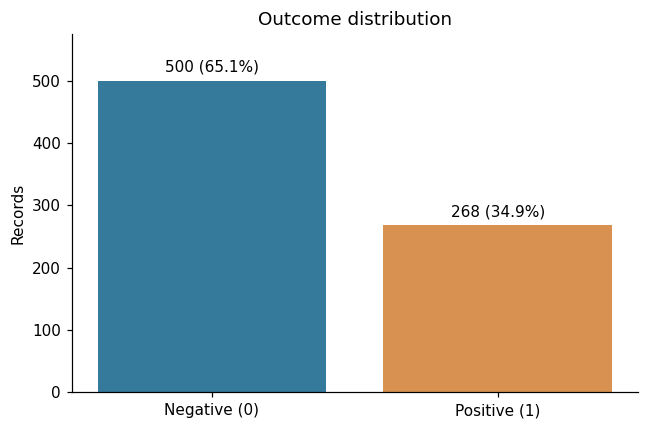

Training records: 614 | Test records: 154


In [ ]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20,random_state=SEED,stratify=y)
assert set(X_train.index).isdisjoint(X_test.index)
assert "Outcome" not in X.columns
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
cv_splits = list(cv.split(X_train,y_train))
split_counts = pd.DataFrame({"Train":y_train.value_counts(),"Test":y_test.value_counts()}).sort_index()
display(split_counts)
print("Training records:",len(X_train),"| Test records:",len(X_test))
manifest = pd.DataFrame({"source_row_index":df.index,"Outcome":y,"split":"train"})
manifest.loc[X_test.index,"split"] = "test"
manifest.to_csv(OUTPUT_DIR/"split_manifest.csv",index=False)

def make_pipeline(model):
    return Pipeline([("imputer",SimpleImputer(strategy="median")),("model",model)])

counts = y.value_counts().sort_index()
fig,ax = plt.subplots(figsize=(6,4))
bars = ax.bar(["Negative (0)","Positive (1)"],counts,color=["#367a9b","#d89150"])
ax.bar_label(bars,labels=[f"{n} ({n/len(y):.1%})" for n in counts],padding=4)
ax.set(title="Outcome distribution",ylabel="Records",ylim=(0,counts.max()*1.15))
save_chart("01_class_distribution.png")

## 4. Baseline Decision Tree: five-fold cross-validation

In [ ]:
baseline = make_pipeline(DecisionTreeClassifier(random_state=SEED))
baseline_scores = cross_val_score(baseline,X_train,y_train,cv=cv_splits,scoring="accuracy",n_jobs=1)
baseline.fit(X_train,y_train)
display(pd.DataFrame({"Fold":np.arange(1,6),"Baseline accuracy":baseline_scores}))
print(f"Baseline CV accuracy: {baseline_scores.mean():.6f} +/- {baseline_scores.std():.6f}")

,Fold,Baseline accuracy
0,1,0.691057
1,2,0.642276
2,3,0.707317
3,4,0.658537
4,5,0.663934


Baseline CV accuracy: 0.672624 +/- 0.023402


## 5. GridSearchCV: evaluate every combination

In [ ]:
search_space = {
    "model__criterion":["gini","entropy"],
    "model__max_depth":[3,5,7,10,None],
    "model__min_samples_split":[2,5,10],
    "model__min_samples_leaf":[1,2,5]
}
grid_search = GridSearchCV(make_pipeline(DecisionTreeClassifier(random_state=SEED)),
    param_grid=search_space,scoring="accuracy",cv=cv_splits,refit=True,n_jobs=1,error_score="raise")
grid_search.fit(X_train,y_train)
print("Grid candidates:",len(ParameterGrid(search_space)))
print("GridSearchCV best parameters:",grid_search.best_params_)
print(f"GridSearchCV best mean CV accuracy: {grid_search.best_score_:.6f}")
grid_results = pd.DataFrame(grid_search.cv_results_)
display(grid_results.sort_values("rank_test_score")[["params","mean_test_score","std_test_score","rank_test_score"]].head(5))

,params,mean_test_score,std_test_score,rank_test_score
0,"{'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}",0.744302,0.010937,1
1,"{'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5}",0.744302,0.010937,1
2,"{'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_leaf': 1, 'model__min_samples_split': 10}",0.744302,0.010937,1
3,"{'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2}",0.744302,0.012085,1
4,"{'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5}",0.744302,0.012085,1


Grid candidates: 90
GridSearchCV best parameters: {'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}
GridSearchCV best mean CV accuracy: 0.744302


## 6. RandomizedSearchCV: sample configurations

In [ ]:
random_search = RandomizedSearchCV(make_pipeline(DecisionTreeClassifier(random_state=SEED)),
    param_distributions=search_space,n_iter=30,scoring="accuracy",cv=cv_splits,
    random_state=SEED,refit=True,n_jobs=1,error_score="raise")
random_search.fit(X_train,y_train)
print("Randomized candidates:",len(random_search.cv_results_["params"]))
print("RandomizedSearchCV best parameters:",random_search.best_params_)
print(f"RandomizedSearchCV best mean CV accuracy: {random_search.best_score_:.6f}")
random_results = pd.DataFrame(random_search.cv_results_)
display(random_results.sort_values("rank_test_score")[["params","mean_test_score","std_test_score","rank_test_score"]].head(5))

,params,mean_test_score,std_test_score,rank_test_score
4,"{'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_depth': 3, 'model__criterion': 'gini'}",0.744302,0.010937,1
15,"{'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_depth': 3, 'model__criterion': 'gini'}",0.744302,0.012085,1
18,"{'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_depth': 3, 'model__criterion': 'entropy'}",0.742676,0.014057,3
8,"{'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_depth': 5, 'model__criterion': 'gini'}",0.723111,0.021399,4
25,"{'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_depth': 5, 'model__criterion': 'gini'}",0.723111,0.021399,4


Randomized candidates: 30
RandomizedSearchCV best parameters: {'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_depth': 3, 'model__criterion': 'gini'}
RandomizedSearchCV best mean CV accuracy: 0.744302


## 7. Train a Random Forest ensemble

In [ ]:
ensemble_settings = {"n_estimators":300,"min_samples_leaf":2,"max_features":"sqrt","random_state":SEED,"n_jobs":1}
ensemble = make_pipeline(RandomForestClassifier(**ensemble_settings))
ensemble_scores = cross_val_score(ensemble,X_train,y_train,cv=cv_splits,scoring="accuracy",n_jobs=1)
ensemble.fit(X_train,y_train)
display(pd.DataFrame({"Fold":np.arange(1,6),"Random Forest accuracy":ensemble_scores}))
print(f"Ensemble CV accuracy: {ensemble_scores.mean():.6f} +/- {ensemble_scores.std():.6f}")
models = {"Baseline Decision Tree":baseline,"Decision Tree - GridSearchCV":grid_search.best_estimator_,
          "Decision Tree - RandomizedSearchCV":random_search.best_estimator_,"Random Forest Ensemble":ensemble}
cv_means = {"Baseline Decision Tree":baseline_scores.mean(),
    "Decision Tree - GridSearchCV":grid_search.best_score_,
    "Decision Tree - RandomizedSearchCV":random_search.best_score_,
    "Random Forest Ensemble":ensemble_scores.mean()}
preferred_name = max(cv_means,key=cv_means.get)
print("Preferred model by training CV accuracy:",preferred_name)
print("No test scores were used to choose model settings.")

,Fold,Random Forest accuracy
0,1,0.764228
1,2,0.756098
2,3,0.804878
3,4,0.747967
4,5,0.770492


Ensemble CV accuracy: 0.768733 +/- 0.019600
Preferred model by training CV accuracy: Random Forest Ensemble
No test scores were used to choose model settings.


## 8. Single required results table

In [ ]:
def clean_params(params):
    return {k.replace("model__",""):v for k,v in params.items()}

param_descriptions = {
    "Baseline Decision Tree":"Fixed, not tuned: criterion=gini, max_depth=None, min_samples_split=2, min_samples_leaf=1",
    "Decision Tree - GridSearchCV":json.dumps(clean_params(grid_search.best_params_)),
    "Decision Tree - RandomizedSearchCV":json.dumps(clean_params(random_search.best_params_)),
    "Random Forest Ensemble":"Fixed, not tuned: n_estimators=300, min_samples_leaf=2, max_features=sqrt, max_depth=None"
}
rows,predictions = [],{}
for name,model in models.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    rows.append({"Model":name,"CV Accuracy":cv_means[name],"Test Accuracy":accuracy_score(y_test,pred),
                 "Best Params":param_descriptions[name]})
results = pd.DataFrame(rows)
display(results)
fold_scores = pd.DataFrame({"Fold":np.arange(1,6),"Baseline Decision Tree":baseline_scores,
    "Decision Tree - GridSearchCV":[grid_search.cv_results_[f"split{i}_test_score"][grid_search.best_index_] for i in range(5)],
    "Decision Tree - RandomizedSearchCV":[random_search.cv_results_[f"split{i}_test_score"][random_search.best_index_] for i in range(5)],
    "Random Forest Ensemble":ensemble_scores})
display(fold_scores)
majority_label = y_train.mode().iloc[0]
print(f"Reference: always predict training majority ({majority_label}) => test accuracy {accuracy_score(y_test,np.full(len(y_test),majority_label)):.6f}")
display(pd.DataFrame({"Model":list(models),"Train Accuracy":[accuracy_score(y_train,m.predict(X_train)) for m in models.values()]}))
print("Class-specific report for the CV-selected model:",preferred_name)
print(classification_report(y_test,predictions[preferred_name],labels=[0,1],target_names=["Negative (0)","Positive (1)"],digits=4,zero_division=0))
print("Confusion matrix, rows=actual and columns=predicted [0,1]:")
print(confusion_matrix(y_test,predictions[preferred_name],labels=[0,1]))

,Model,CV Accuracy,Test Accuracy,Best Params
0,Baseline Decision Tree,0.672624,0.681818,"Fixed, not tuned: criterion=gini, max_depth=None, min_samples_split=2, min_samples_leaf=1"
1,Decision Tree - GridSearchCV,0.744302,0.688312,"{""criterion"": ""gini"", ""max_depth"": 3, ""min_samples_leaf"": 1, ""min_samples_split"": 2}"
2,Decision Tree - RandomizedSearchCV,0.744302,0.688312,"{""min_samples_split"": 2, ""min_samples_leaf"": 1, ""max_depth"": 3, ""criterion"": ""gini""}"
3,Random Forest Ensemble,0.768733,0.746753,"Fixed, not tuned: n_estimators=300, min_samples_leaf=2, max_features=sqrt, max_depth=None"


,Fold,Baseline Decision Tree,Decision Tree - GridSearchCV,Decision Tree - RandomizedSearchCV,Random Forest Ensemble
0,1,0.691057,0.764228,0.764228,0.764228
1,2,0.642276,0.731707,0.731707,0.756098
2,3,0.707317,0.739837,0.739837,0.804878
3,4,0.658537,0.739837,0.739837,0.747967
4,5,0.663934,0.745902,0.745902,0.770492


,Model,Train Accuracy
0,Baseline Decision Tree,1.000000
1,Decision Tree - GridSearchCV,0.768730
2,Decision Tree - RandomizedSearchCV,0.768730
3,Random Forest Ensemble,0.975570


Reference: always predict training majority (0) => test accuracy 0.649351
Class-specific report for the CV-selected model: Random Forest Ensemble
              precision    recall  f1-score   support

Negative (0)     0.7798    0.8500    0.8134       100
Positive (1)     0.6667    0.5556    0.6061        54

    accuracy                         0.7468       154
   macro avg     0.7232    0.7028    0.7097       154
weighted avg     0.7401    0.7468    0.7407       154

Confusion matrix, rows=actual and columns=predicted [0,1]:
[[85 15]
 [24 30]]


## 9. Visualize and interpret the comparison

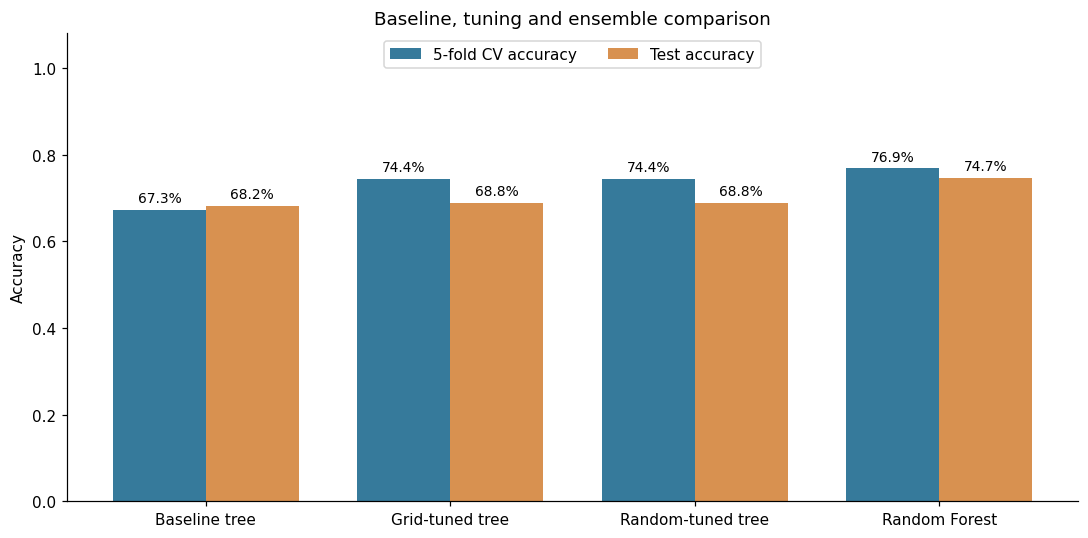

Random Forest Ensemble had the highest mean training CV accuracy (76.87%) and achieved 74.68% on the held-out test set. The highest observed test accuracy was 74.68% for Random Forest Ensemble; this is a descriptive result from one split, not a reason to retune on the test set. Grid search evaluated 90 candidates and randomized search evaluated 30, illustrating the trade-off between exhaustive coverage and a smaller search budget.


In [ ]:
labels = ["Baseline tree","Grid-tuned tree","Random-tuned tree","Random Forest"]
x = np.arange(len(labels))
fig,ax = plt.subplots(figsize=(10,5))
b1 = ax.bar(x-0.19,results["CV Accuracy"],0.38,label="5-fold CV accuracy",color="#367a9b")
b2 = ax.bar(x+0.19,results["Test Accuracy"],0.38,label="Test accuracy",color="#d89150")
ax.bar_label(b1,labels=[f"{v:.1%}" for v in results["CV Accuracy"]],padding=3,fontsize=9)
ax.bar_label(b2,labels=[f"{v:.1%}" for v in results["Test Accuracy"]],padding=3,fontsize=9)
ax.set(xticks=x,xticklabels=labels,ylabel="Accuracy",ylim=(0,1.08),title="Baseline, tuning and ensemble comparison")
ax.legend(loc="upper center",ncol=2)
save_chart("02_cv_test_accuracy.png")
best_test = results.loc[results["Test Accuracy"].idxmax()]
preferred = results.set_index("Model").loc[preferred_name]
summary = (
    f"{preferred_name} had the highest mean training CV accuracy ({preferred['CV Accuracy']:.2%}) and "
    f"achieved {preferred['Test Accuracy']:.2%} on the held-out test set. "
    f"The highest observed test accuracy was {best_test['Test Accuracy']:.2%} for {best_test['Model']}; "
    "this is a descriptive result from one split, not a reason to retune on the test set. "
    f"Grid search evaluated {len(grid_results)} candidates and randomized search evaluated {len(random_results)}, "
    "illustrating the trade-off between exhaustive coverage and a smaller search budget."
)
print(summary)

Random Forest Ensemble had the highest mean training CV accuracy (76.87%) and achieved 74.68% on the held-out test set. The highest observed test accuracy was 74.68% for Random Forest Ensemble; this is a descriptive result from one split, not a reason to retune on the test set. Grid search evaluated 90 candidates and randomized search evaluated 30, illustrating the trade-off between exhaustive coverage and a smaller search budget.

## 10. Export the deliverables

In [ ]:
results.to_csv(OUTPUT_DIR/"tuning_ensemble_results.csv",index=False)
grid_results.to_csv(OUTPUT_DIR/"grid_search_trials.csv",index=False)
random_results.to_csv(OUTPUT_DIR/"randomized_search_trials.csv",index=False)
fold_scores.to_csv(OUTPUT_DIR/"cv_fold_scores.csv",index=False)
pd.DataFrame({"Actual":y_test,**predictions}).rename_axis("source_row_index").to_csv(OUTPUT_DIR/"test_predictions.csv")
settings = {"seed":SEED,"test_fraction":0.20,"cv_folds":5,"input_sha256":input_hash,
    "preferred_by_cv":preferred_name,"search_space":search_space,"randomized_n_iter":30,
    "grid_best_params":grid_search.best_params_,"grid_best_score":grid_search.best_score_,
    "randomized_best_params":random_search.best_params_,"randomized_best_score":random_search.best_score_,
    "estimators":{name:model.named_steps["model"].get_params() for name,model in models.items()}}
(OUTPUT_DIR/"experiment_settings.json").write_text(json.dumps(settings,indent=2))
(OUTPUT_DIR/"conclusion.md").write_text("# Results interpretation\n\n"+summary+"\n",encoding="utf-8")
assert results.shape==(4,4)
assert results[["CV Accuracy","Test Accuracy"]].ge(0).all().all()
assert results[["CV Accuracy","Test Accuracy"]].le(1).all().all()
assert all(len(p)==len(y_test) for p in predictions.values())
print("Saved results, search trials, fold scores, predictions, charts and settings to",OUTPUT_DIR.resolve())

Saved results, search trials, fold scores, predictions, charts and settings to /workspace/scratch/280081ade6a3/diabetes-tuning-ensemble/outputs
